# Práctica 4 — Tarea 2: Reconocimiento de matrículas (OCR) y entrega

Se comparan dos formas de leer el texto de las matrículas:

* **OCR clásico:** [EasyOCR](https://github.com/JaidedAI/EasyOCR), una red especializada en detectar y reconocer texto.
* **VLM:** [SmolVLM-256M-Instruct](https://huggingface.co/HuggingFaceTB/SmolVLM-256M-Instruct), un modelo de visión y lenguaje al que se le pregunta qué pone en la matrícula.

Después se usa el mejor de los dos para leer las matrículas del vídeo de la Tarea 1 y completar la columna `texto_matricula` del CSV.

Instalaciones previas

In [3]:
# EasyOCR se instala sin dependencias para que no sustituya opencv-python por opencv-python-headless
# (eso eliminaría cv2.imshow, como avisa el enunciado).
#%pip install transformers scipy scikit-image python-bidi PyYAML Shapely pyclipper ninja
#%pip install --no-deps easyocr

Paquetes necesarios

In [4]:
import os
import re
import csv
import time
import platform
from collections import Counter, defaultdict

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

CONFIGURACIÓN (rutas y parámetros)

In [5]:
# Rutas (relativas a la carpeta TAREAS/)
VIDEO_PATH       = '../videos/C0142.MP4'
DATASET_DIR      = '../dataset'
GROUND_TRUTH_CSV = '../dataset/ground_truth.csv'

CARPETA_RESULTADOS = '../resultados'
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)
CSV_TAREA_1  = os.path.join(CARPETA_RESULTADOS, 'resultado.csv')       # salida de la Tarea 1
SALIDA_VIDEO = os.path.join(CARPETA_RESULTADOS, 'resultado_ocr.mp4')
SALIDA_CSV   = os.path.join(CARPETA_RESULTADOS, 'resultado_ocr.csv')

DEVICE    = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE_VLM = torch.float16 if DEVICE == 'cuda' else torch.float32

N_COMPARATIVA = 200   # matrículas de test usadas en la comparativa (mismas para los dos modelos)
SEMILLA       = 42
print('Dispositivo:', DEVICE)

Dispositivo: cuda


---
# PARTE 3: OCR DE MATRÍCULAS

PASO 3.1: POSTPROCESADO DEL TEXTO (formato de matrícula española)

Ambos modelos cometen errores parecidos, así que se les aplica **el mismo postprocesado**:

1. Se pasa a mayúsculas y se quitan espacios, guiones y puntos.
2. Si el texto no tiene ya un formato válido, se busca una ventana de 7 caracteres que pueda ser `0000XXX`, corrigiendo las confusiones típicas según la posición: en la parte numérica `O→0`, `I→1`, `B→8`, `S→5`…, y en la parte de letras `0→D`, `8→B`, `5→S`…

Esto elimina, por ejemplo, la `E` o la `L` que se leen a veces en la banda azul europea de la izquierda.

In [6]:
def normalizar(texto):
    """Mayúsculas y solo letras y números."""
    return re.sub(r'[^A-Z0-9]', '', str(texto).upper())


A_DIGITO = str.maketrans({'O': '0', 'Q': '0', 'D': '0', 'U': '0', 'I': '1', 'L': '1', 'J': '1', 'T': '1',
                          'Z': '2', 'S': '5', 'B': '8', 'G': '6', 'A': '4'})
A_LETRA  = str.maketrans({'0': 'D', '1': 'J', '2': 'Z', '5': 'S', '8': 'B', '6': 'G', '4': 'A', '7': 'T'})
FORMATO_ACTUAL  = re.compile(r'\d{4}[A-Z]{3}')              # 1234ABC
FORMATO_ANTIGUO = re.compile(r'[A-Z]{1,2}\d{4}[A-Z]{1,2}')  # GC1234AB


def es_valida(texto):
    return bool(FORMATO_ACTUAL.fullmatch(texto) or FORMATO_ANTIGUO.fullmatch(texto))


def limpiar_texto(texto):
    """Normaliza y corrige el texto leído según el formato de matrícula española."""
    t = normalizar(texto)
    if es_valida(t):
        return t
    for i in range(0, max(1, len(t) - 6)):
        ventana = t[i:i + 7]
        if len(ventana) < 7:
            break
        candidata = ventana[:4].translate(A_DIGITO) + ventana[4:].translate(A_LETRA)
        if FORMATO_ACTUAL.fullmatch(candidata):
            return candidata
    return t


for ejemplo in ['E 1234 BCD', '1Z34-8CD.', 'L5805MRJ', 'GC 6744 AK', '7657 NELP']:
    print(f'{ejemplo!r:14s} -> {limpiar_texto(ejemplo)}')

'E 1234 BCD'   -> 1234BCD
'1Z34-8CD.'    -> 1234BCD
'L5805MRJ'     -> 1580SMR
'GC 6744 AK'   -> GC6744AK
'7657 NELP'    -> 7657NEL


PASO 3.2: OCR CLÁSICO (EasyOCR)

* Se restringe el alfabeto a `A-Z` y `0-9`.
* Si la matrícula es pequeña, el recorte se **amplía** hasta 100 px de alto: en las pruebas previas subió el acierto del 34 % al 36 % con apenas 10 ms más.
* EasyOCR puede devolver varios trozos de texto (por ejemplo, números y letras por separado); se ordenan de izquierda a derecha y se unen.

In [7]:
import easyocr

lector = easyocr.Reader(['en'], gpu=(DEVICE == 'cuda'), verbose=False)
ALFABETO = '0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ'


def leer_matricula_ocr(recorte, alto_minimo=100):
    """Devuelve el texto leído por EasyOCR (sin postprocesar)."""
    if recorte.shape[0] < alto_minimo:
        f = alto_minimo / recorte.shape[0]
        recorte = cv2.resize(recorte, None, fx=f, fy=f, interpolation=cv2.INTER_CUBIC)
    trozos = lector.readtext(recorte, allowlist=ALFABETO, detail=1)
    trozos = sorted(trozos, key=lambda t: t[0][0][0])        # de izquierda a derecha
    return ''.join(texto for _, texto, _ in trozos)

PASO 3.3: VLM (SmolVLM-256M-Instruct)

* Se usa la versión de **256M parámetros**, la única que cabe con holgura en una GPU de 3 GB. La de 500M tardaba 12.7 s por matrícula y apenas acertaba más; la de 2B (la del cuaderno de ejemplo) no cabe.
* Se mantiene el **troceado de la imagen** (`do_image_splitting`) que hace el procesador de SmolVLM: sin él era más rápido, pero el acierto bajaba del 62 % al 50 % y a veces inventaba textos largos.
* La respuesta se limita a 16 tokens y sin muestreo (`do_sample=False`), para que sea determinista.

In [8]:
from transformers import AutoProcessor, AutoModelForImageTextToText

NOMBRE_VLM = 'HuggingFaceTB/SmolVLM-256M-Instruct'
procesador_vlm = AutoProcessor.from_pretrained(NOMBRE_VLM)
modelo_vlm = AutoModelForImageTextToText.from_pretrained(
    NOMBRE_VLM, dtype=DTYPE_VLM, attn_implementation='eager').to(DEVICE).eval()

PREGUNTA = 'Read the license plate in the image. Answer only with its characters.'


def leer_matricula_vlm(recorte):
    """Devuelve la respuesta del VLM (sin postprocesar)."""
    imagen = Image.fromarray(cv2.cvtColor(recorte, cv2.COLOR_BGR2RGB))
    mensajes = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': PREGUNTA}]}]
    prompt = procesador_vlm.apply_chat_template(mensajes, add_generation_prompt=True)
    entradas = procesador_vlm(text=prompt, images=[imagen], return_tensors='pt').to(DEVICE, DTYPE_VLM)
    with torch.no_grad():
        salida = modelo_vlm.generate(**entradas, max_new_tokens=16, do_sample=False)
    nuevos = salida[:, entradas['input_ids'].shape[1]:]          # solo la respuesta, sin el prompt
    return procesador_vlm.batch_decode(nuevos, skip_special_tokens=True)[0].strip()

c:\Users\Usuario\miniconda3\envs\VC_PRACTICA_4\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 471/471 [00:00<00:00, 528.71it/s]


PASO 3.4: GROUND TRUTH Y RECORTES DE TEST

El texto real de cada matrícula está en `dataset/ground_truth.csv`, generado a partir de las anotaciones del dataset. Para la comparativa:

* Solo se usan matrículas del **split de test** (no vistas al entrenar el detector) y **legibles**.
* Se toman `N_COMPARATIVA` al azar con semilla fija, y **las mismas** para los dos modelos.
* Se recortan con la caja anotada (más un 5 % de margen), para medir solo la calidad del OCR y no los fallos del detector.

Matrículas legibles en test: 658 | usadas en la comparativa: 200


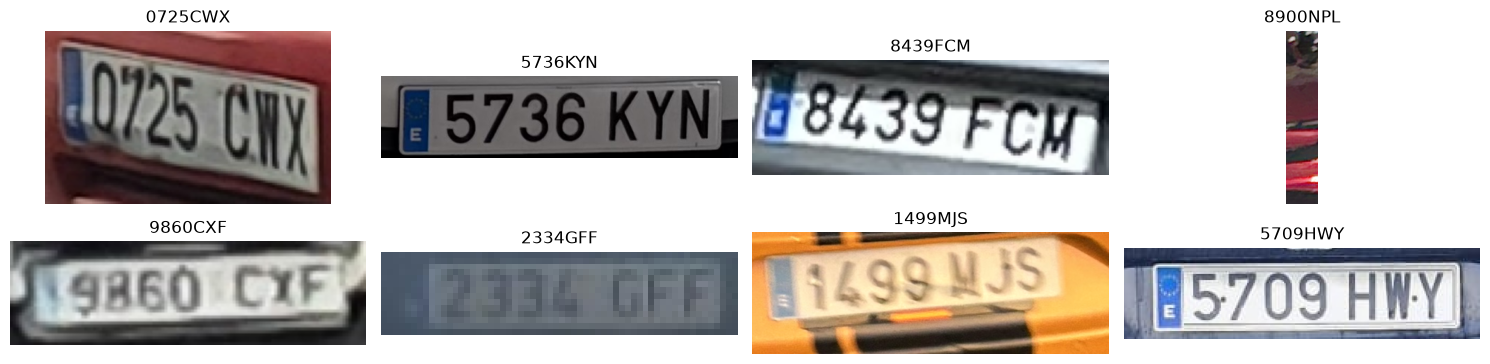

In [9]:
gt = pd.read_csv(GROUND_TRUTH_CSV)
gt_test = gt[(gt.split == 'test') & (gt.legible == 1)]
muestra = gt_test.sample(min(N_COMPARATIVA, len(gt_test)), random_state=SEMILLA).reset_index(drop=True)
print(f'Matrículas legibles en test: {len(gt_test)} | usadas en la comparativa: {len(muestra)}')


def recortar_matricula(fila, margen=0.05):
    img = cv2.imread(os.path.join(DATASET_DIR, 'test', 'images', fila.imagen))
    h, w = img.shape[:2]
    bw, bh = fila.w * w, fila.h * h
    x1, y1 = int(fila.cx * w - bw / 2 - margen * bw), int(fila.cy * h - bh / 2 - margen * bh)
    x2, y2 = int(fila.cx * w + bw / 2 + margen * bw), int(fila.cy * h + bh / 2 + margen * bh)
    return img[max(0, y1):y2, max(0, x1):x2]


recortes = [recortar_matricula(f) for f in muestra.itertuples()]
reales = muestra.matricula.tolist()

plt.figure(figsize=(15, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(cv2.cvtColor(recortes[i], cv2.COLOR_BGR2RGB))
    plt.title(reales[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

PASO 3.5: COMPARATIVA OCR CLÁSICO vs VLM

Métricas:

* **Acierto exacto:** porcentaje de matrículas leídas perfectamente (se da sin y con postprocesado).
* **CER (Character Error Rate):** distancia de edición entre el texto leído y el real, dividida por el número de caracteres reales. Es más justo que el acierto exacto: fallar un carácter de siete no es un fallo total.
* **Tiempo de inferencia por matrícula**, medido con `time.perf_counter()` tras 3 llamadas de calentamiento (*warm-up*), que no se cuentan porque la primera llamada incluye inicializaciones.

In [10]:
def distancia_edicion(a, b):
    """Distancia de Levenshtein: nº mínimo de inserciones, borrados y sustituciones para pasar de a a b."""
    anterior = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        actual = [i]
        for j, cb in enumerate(b, 1):
            actual.append(min(anterior[j] + 1, actual[j - 1] + 1, anterior[j - 1] + (ca != cb)))
        anterior = actual
    return anterior[-1]


def evaluar(nombre, funcion_ocr):
    for r in recortes[:3]:                    # warm-up
        funcion_ocr(r)
    filas = []
    for recorte, real in zip(recortes, reales):
        t0 = time.perf_counter()
        crudo = funcion_ocr(recorte)
        t = time.perf_counter() - t0
        filas.append({'modelo': nombre, 'real': real, 'crudo': crudo,
                      'normalizado': normalizar(crudo), 'corregido': limpiar_texto(crudo), 'tiempo_s': t})
    df = pd.DataFrame(filas)
    print(f'{nombre}: {len(df)} matrículas en {df.tiempo_s.sum():.1f} s')
    return df


res_ocr = evaluar('EasyOCR', leer_matricula_ocr)
res_vlm = evaluar('SmolVLM-256M', leer_matricula_vlm)
comparativa = pd.concat([res_ocr, res_vlm], ignore_index=True)
comparativa.to_csv(os.path.join(CARPETA_RESULTADOS, 'comparativa_ocr.csv'), index=False)

resumen = []
for nombre, df in comparativa.groupby('modelo', sort=False):
    n_car = df.real.str.len().sum()
    resumen.append({
        'modelo': nombre,
        'acierto_exacto_sin_post': (df.normalizado == df.real).mean(),
        'acierto_exacto': (df.corregido == df.real).mean(),
        'CER': sum(distancia_edicion(p, r) for p, r in zip(df.corregido, df.real)) / n_car,
        'tiempo_medio_ms': df.tiempo_s.mean() * 1000,
        'tiempo_mediana_ms': df.tiempo_s.median() * 1000,
    })
resumen = pd.DataFrame(resumen).set_index('modelo')
resumen.to_csv(os.path.join(CARPETA_RESULTADOS, 'resumen_comparativa_ocr.csv'))
display(resumen.style.format({'acierto_exacto_sin_post': '{:.1%}', 'acierto_exacto': '{:.1%}', 'CER': '{:.3f}',
                              'tiempo_medio_ms': '{:.0f}', 'tiempo_mediana_ms': '{:.0f}'}))

EasyOCR: 200 matrículas en 13.7 s
SmolVLM-256M: 200 matrículas en 1272.2 s


,acierto_exacto_sin_post,acierto_exacto,CER,tiempo_medio_ms,tiempo_mediana_ms
modelo,,,,,
EasyOCR,33.0%,38.5%,0.284,69,54
SmolVLM-256M,60.5%,62.0%,0.163,6361,5956


Ejemplos de lecturas (real / EasyOCR / SmolVLM):

In [11]:
lado_a_lado = pd.DataFrame({'real': reales,
                            'EasyOCR': res_ocr.corregido, 'SmolVLM': res_vlm.corregido,
                            'EasyOCR_crudo': res_ocr.crudo, 'SmolVLM_crudo': res_vlm.crudo})
lado_a_lado['acierta_EasyOCR'] = lado_a_lado.EasyOCR == lado_a_lado.real
lado_a_lado['acierta_SmolVLM'] = lado_a_lado.SmolVLM == lado_a_lado.real
print('Solo acierta EasyOCR :', (lado_a_lado.acierta_EasyOCR & ~lado_a_lado.acierta_SmolVLM).sum())
print('Solo acierta SmolVLM :', (~lado_a_lado.acierta_EasyOCR & lado_a_lado.acierta_SmolVLM).sum())
print('Aciertan los dos     :', (lado_a_lado.acierta_EasyOCR & lado_a_lado.acierta_SmolVLM).sum())
print('Fallan los dos       :', (~lado_a_lado.acierta_EasyOCR & ~lado_a_lado.acierta_SmolVLM).sum())
display(lado_a_lado.head(15))

Solo acierta EasyOCR : 13
Solo acierta SmolVLM : 60
Aciertan los dos     : 64
Fallan los dos       : 63


,real,EasyOCR,SmolVLM,EasyOCR_crudo,SmolVLM_crudo,acierta_EasyOCR,acierta_SmolVLM
0,0725CWX,02CHA,0725CWX,02CHA,0725 CWX,False,True
1,5736KYN,5736KYN,5736KYN,5736KYN,5736 KYN.,True,True
2,8439FCM,8439FCM,8439FCM,8439FCM,8439 FCM,True,True
3,8900NPL,,03001,,03001,False,False
4,9860CXF,93600F,9860CXF,93600F,9860 CXF,False,True
5,2334GFF,2334GFD,2340FF,2334GF0,2340FF,False,False
6,1499MJS,DTH,1499MJS,DTH,1499 MJS.,False,True
7,5709HWY,5709HWY,5709HWY,5709HWY,5709 hwy.,True,True
8,7632NPP,7632NPP,7632NPP,7632NPP,7632 NPP,True,True
9,0459GHG,0459GHO,0459CHG,10459GHO,0459 chg,False,False


PASO 3.6: GRÁFICAS DE LA COMPARATIVA

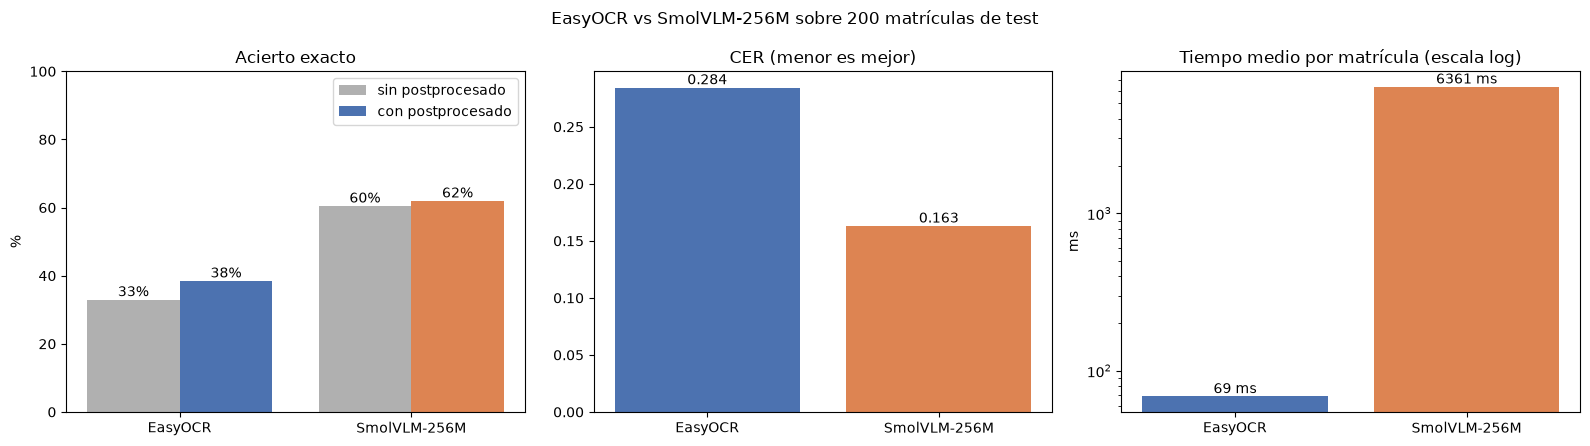

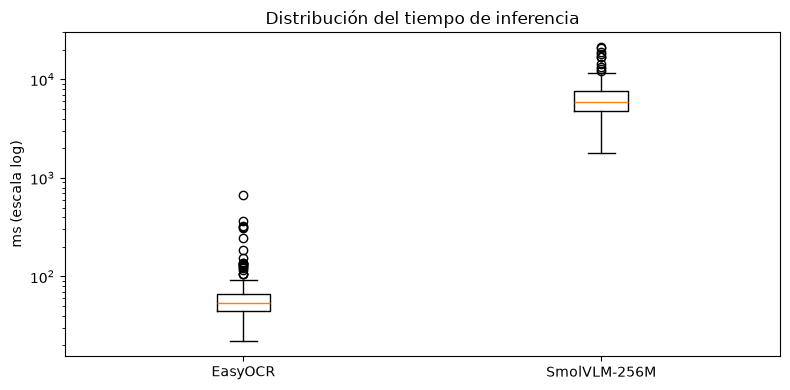

In [12]:
modelos = resumen.index.tolist()
colores = ['#4C72B0', '#DD8452']
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))

# Acierto exacto (sin y con postprocesado)
x = np.arange(len(modelos))
b1 = ejes[0].bar(x - 0.2, resumen.acierto_exacto_sin_post * 100, 0.4, label='sin postprocesado', color='#B0B0B0')
b2 = ejes[0].bar(x + 0.2, resumen.acierto_exacto * 100, 0.4, label='con postprocesado', color=colores)
ejes[0].bar_label(b1, fmt='%.0f%%'); ejes[0].bar_label(b2, fmt='%.0f%%')
ejes[0].set_xticks(x, modelos); ejes[0].set_ylabel('%'); ejes[0].set_ylim(0, 100)
ejes[0].set_title('Acierto exacto'); ejes[0].legend()

# CER
b = ejes[1].bar(modelos, resumen.CER, color=colores)
ejes[1].bar_label(b, fmt='%.3f'); ejes[1].set_title('CER (menor es mejor)')

# Tiempo (escala logarítmica: la diferencia es de dos órdenes de magnitud)
b = ejes[2].bar(modelos, resumen.tiempo_medio_ms, color=colores)
ejes[2].bar_label(b, fmt='%.0f ms'); ejes[2].set_yscale('log')
ejes[2].set_title('Tiempo medio por matrícula (escala log)'); ejes[2].set_ylabel('ms')

plt.suptitle(f'EasyOCR vs SmolVLM-256M sobre {len(muestra)} matrículas de test')
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_RESULTADOS, 'comparativa_ocr.png'), dpi=120)
plt.show()

# Distribución de tiempos
plt.figure(figsize=(8, 4))
plt.boxplot([res_ocr.tiempo_s * 1000, res_vlm.tiempo_s * 1000], tick_labels=modelos)
plt.yscale('log'); plt.ylabel('ms (escala log)'); plt.title('Distribución del tiempo de inferencia')
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_RESULTADOS, 'tiempos_ocr.png'), dpi=120)
plt.show()

PASO 3.7: OCR EN EL VÍDEO (completa el CSV y el vídeo de la Tarea 1)

Se parte del CSV de la Tarea 1, que ya contiene la caja de cada matrícula detectada. Pasar el VLM por las 1300 detecciones tardaría más de una hora, así que:

1. Para cada vehículo (ID de tracking) se eligen sus **`K` mejores vistas** de la matrícula: las de mayor tamaño (cuando el coche está más cerca) y, a igualdad, mayor confianza.
2. Se leen con el modelo elegido y se postprocesan.
3. La matrícula del vehículo es la **lectura más votada**, dando preferencia a las que tienen un formato válido.
4. Ese texto se escribe en la columna `texto_matricula` de todas las filas del vehículo con matrícula y se dibuja en el vídeo junto al vehículo.

In [13]:
K_VISTAS = 3
LECTOR_VIDEO = leer_matricula_vlm          # el más preciso en la comparativa (cambiar a leer_matricula_ocr si se prefiere velocidad)

df = pd.read_csv(CSV_TAREA_1, keep_default_na=False)
con_mat = df[df.matricula_en_su_caso == 'si'].copy()
for c in ['mx1', 'my1', 'mx2', 'my2']:
    con_mat[c] = con_mat[c].astype(int)
con_mat['area'] = (con_mat.mx2 - con_mat.mx1) * (con_mat.my2 - con_mat.my1)
con_mat['confianza_matricula'] = con_mat.confianza_matricula.astype(float)

# K mejores vistas por vehículo
mejores = (con_mat.sort_values(['area', 'confianza_matricula'], ascending=False)
                  .groupby('identificador_tracking').head(K_VISTAS))
pendientes = defaultdict(list)      # fotograma -> filas a leer en ese fotograma
for fila in mejores.itertuples():
    pendientes[fila.fotograma].append(fila)
print(f'Vehículos con matrícula: {con_mat.identificador_tracking.nunique()} | lecturas a hacer: {len(mejores)}')

# Recorrer el vídeo y leer solo en los fotogramas necesarios
lecturas = defaultdict(list)        # id -> [(texto corregido, confianza detección)]
cap = cv2.VideoCapture(VIDEO_PATH)
n, t0 = 0, time.time()
ultimo = max(pendientes) if pendientes else -1
while n <= ultimo:
    ok, frame = cap.read()
    if not ok:
        break
    for fila in pendientes.get(n, []):
        recorte = frame[max(0, fila.my1):fila.my2, max(0, fila.mx1):fila.mx2]
        if recorte.size:
            lecturas[fila.identificador_tracking].append((limpiar_texto(LECTOR_VIDEO(recorte)), fila.confianza_matricula))
    n += 1
cap.release()
print(f'Lecturas hechas en {time.time() - t0:.0f} s')


def votar(lista):
    """Lectura más repetida, priorizando formatos válidos y, a igualdad, la de mayor confianza."""
    validas = [l for l in lista if es_valida(l[0])]
    candidatas = validas or [l for l in lista if l[0]]
    if not candidatas:
        return ''
    votos = Counter(t for t, _ in candidatas)
    return max(votos, key=lambda t: (votos[t], max(c for tt, c in candidatas if tt == t)))


texto_por_id = {tid: votar(l) for tid, l in lecturas.items()}
for tid, l in sorted(lecturas.items()):
    print(f'  #{tid:<4d} lecturas {[t for t, _ in l]} -> {texto_por_id[tid] or "(sin lectura)"}')
print(f'\nVehículos con texto de matrícula: {sum(1 for t in texto_por_id.values() if t)} de {len(texto_por_id)}')

Vehículos con matrícula: 31 | lecturas a hacer: 89
Lecturas hechas en 636 s
  #1    lecturas ['0370JZS', '12345', '1234SGT'] -> 1234SGT
  #8    lecturas ['0000DDD', '0000DDD', '0000DDD'] -> 0000DDD
  #10   lecturas ['B12345', '1234SGT', '1234SGT'] -> 1234SGT
  #11   lecturas ['667000', '6600JTT', '5000'] -> 6600JTT
  #12   lecturas ['1234SGT', '0000DDD', '6600DDD'] -> 6600DDD
  #13   lecturas ['0123ASG', '0000DDD', '667000'] -> 0123ASG
  #14   lecturas ['12345', '667000', '1234SGT'] -> 1234SGT
  #16   lecturas ['0000DDD', '000000', '667000'] -> 0000DDD
  #18   lecturas ['6600DDD', '2021DJD', '2222ZZZ'] -> 2222ZZZ
  #19   lecturas ['AA12345', '1234SGT', '667000'] -> 1234SGT
  #22   lecturas ['1234SGT', '1234SGT', '0000DDD'] -> 1234SGT
  #24   lecturas ['0123ASG', '1234SGT', '12345'] -> 1234SGT
  #25   lecturas ['12345', '2522', '2152'] -> 2152
  #27   lecturas ['A7879', '777000', '7007DDT'] -> 7007DDT
  #29   lecturas ['0000DDD'] -> 0000DDD
  #30   lecturas ['12345', '12345', '12345'] -

Vídeo y CSV finales con el texto de la matrícula:

CSV guardado: ../resultados\resultado_ocr.csv (1312 filas con texto)
Vídeo guardado: ../resultados\resultado_ocr.mp4


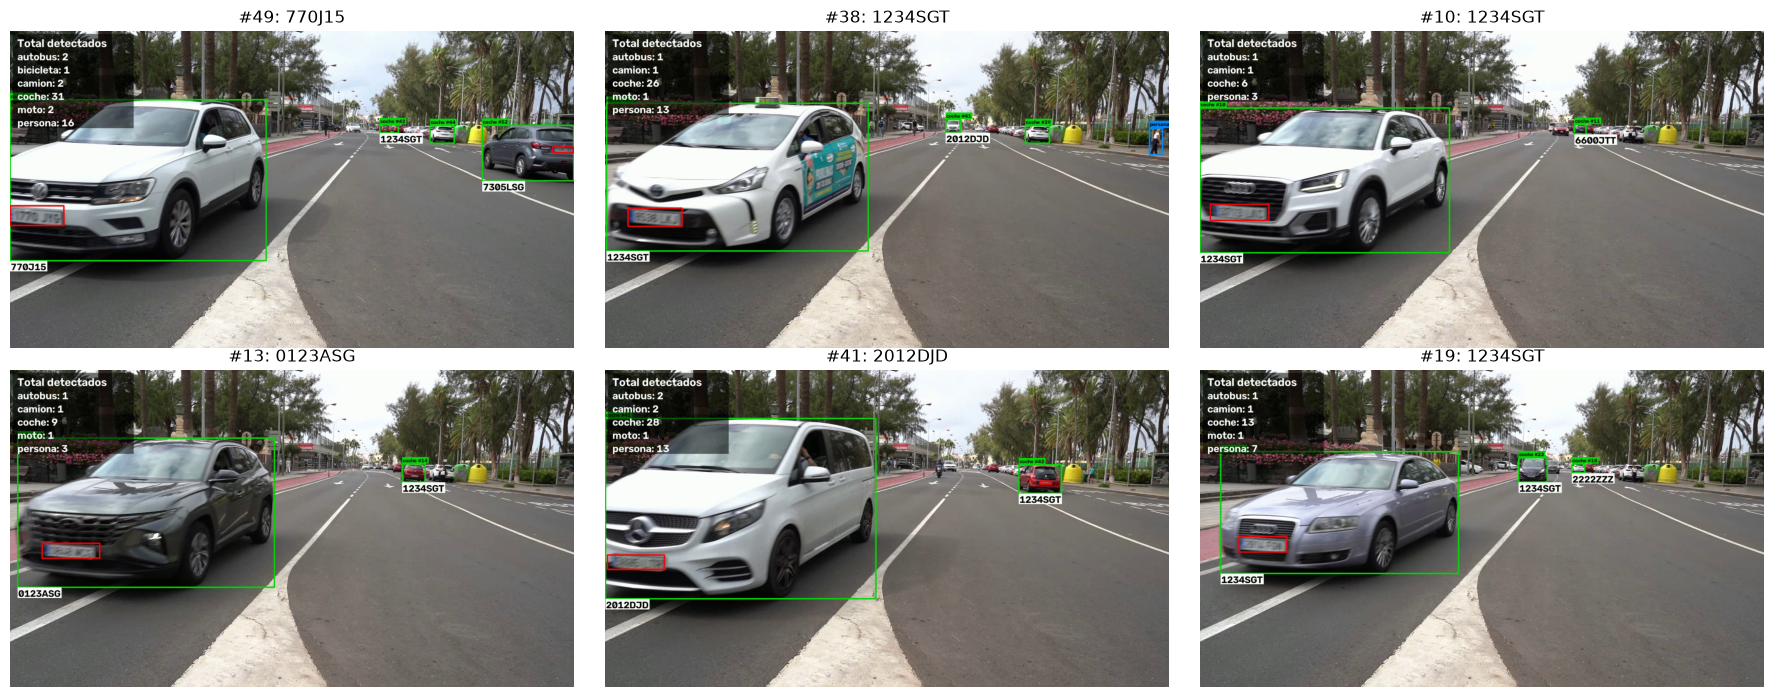

In [14]:
# CSV: texto_matricula en las filas con matrícula detectada
df['texto_matricula'] = [texto_por_id.get(tid, '') if m == 'si' else ''
                         for tid, m in zip(df.identificador_tracking, df.matricula_en_su_caso)]
df.to_csv(SALIDA_CSV, index=False)
print(f'CSV guardado: {SALIDA_CSV} ({(df.texto_matricula != "").sum()} filas con texto)')

# Vídeo: se redibuja a partir del CSV añadiendo el texto
COLORES = {'persona': (255, 140, 0), 'bicicleta': (0, 200, 255), 'coche': (0, 220, 0),
           'moto': (255, 0, 255), 'autobus': (0, 140, 255), 'camion': (255, 255, 0)}


def etiqueta(img, texto, x, y, fondo, color_texto=(0, 0, 0), escala=0.6, grosor=2):
    (tw, th), base = cv2.getTextSize(texto, cv2.FONT_HERSHEY_SIMPLEX, escala, grosor)
    y = max(y, th + base + 2)
    cv2.rectangle(img, (x, y - th - base - 2), (x + tw + 4, y + 2), fondo, -1)
    cv2.putText(img, texto, (x + 2, y - base), cv2.FONT_HERSHEY_SIMPLEX, escala, color_texto, grosor, cv2.LINE_AA)


por_fotograma = {k: g for k, g in df.groupby('fotograma')}
cap = cv2.VideoCapture(VIDEO_PATH)
fps = cap.get(cv2.CAP_PROP_FPS)
ancho, alto = int(cap.get(3)), int(cap.get(4))
tam_salida = (1280, int(alto * 1280 / ancho))
writer = cv2.VideoWriter(SALIDA_VIDEO, cv2.VideoWriter_fourcc(*'mp4v'), fps, tam_salida)
vistos = defaultdict(set)
n = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    for f in por_fotograma.get(n, pd.DataFrame()).itertuples():
        color = COLORES.get(f.tipo_objeto, (200, 200, 200))
        vistos[f.tipo_objeto].add(f.identificador_tracking)
        cv2.rectangle(frame, (f.x1, f.y1), (f.x2, f.y2), color, 3)
        etiqueta(frame, f'{f.tipo_objeto} #{f.identificador_tracking}', f.x1, f.y1 - 4, color)
        texto = texto_por_id.get(f.identificador_tracking, '')
        if f.matricula_en_su_caso == 'si':
            mx1, my1, mx2, my2 = int(f.mx1), int(f.my1), int(f.mx2), int(f.my2)
            cv2.rectangle(frame, (mx1, my1), (mx2, my2), (0, 0, 255), 3)
        if texto:   # texto de la matrícula bajo el vehículo durante todo su recorrido
            etiqueta(frame, texto, f.x1, f.y2 + 34, (255, 255, 255), escala=1.1, grosor=3)
    # Panel de conteo
    capa = frame.copy()
    lineas = [f'{k}: {len(v)}' for k, v in sorted(vistos.items())]
    cv2.rectangle(capa, (10, 10), (420, 60 + 45 * len(lineas)), (0, 0, 0), -1)
    frame = cv2.addWeighted(capa, 0.55, frame, 0.45, 0)
    cv2.putText(frame, 'Total detectados', (25, 55), cv2.FONT_HERSHEY_SIMPLEX, 1.3, (255, 255, 255), 3, cv2.LINE_AA)
    for k, linea in enumerate(lineas):
        cv2.putText(frame, linea, (25, 100 + 45 * k), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 3, cv2.LINE_AA)
    writer.write(cv2.resize(frame, tam_salida))
    n += 1
cap.release()
writer.release()
print('Vídeo guardado:', SALIDA_VIDEO)

# Algunos fotogramas con el texto leído
ids_con_texto = [tid for tid, t in texto_por_id.items() if t]
ejemplos = (df[(df.matricula_en_su_caso == 'si') & df.identificador_tracking.isin(ids_con_texto)]
            .assign(area=lambda d: (d.mx2.astype(int) - d.mx1.astype(int)) * (d.my2.astype(int) - d.my1.astype(int)))
            .sort_values('area', ascending=False).drop_duplicates('identificador_tracking').head(6))
cap = cv2.VideoCapture(SALIDA_VIDEO)
plt.figure(figsize=(18, 7))
for i, f in enumerate(ejemplos.itertuples()):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f.fotograma)
    ok, img = cap.read()
    if ok:
        cv2.imwrite(os.path.join(CARPETA_RESULTADOS, f'ocr_frame_{f.fotograma}.jpg'), img)
        plt.subplot(2, 3, i + 1)
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(f'#{f.identificador_tracking}: {texto_por_id[f.identificador_tracking]}')
        plt.axis('off')
cap.release()
plt.tight_layout()
plt.show()

---
# PARTE 4: ENTREGA

PASO 4.1: ESPECIFICACIONES DE LA MÁQUINA

In [15]:
import psutil
import ultralytics
import transformers

especificaciones = {
    'Sistema operativo': platform.platform(),
    'CPU': f'{platform.processor()} ({psutil.cpu_count(logical=False)} núcleos / {os.cpu_count()} hilos)',
    'RAM': f'{psutil.virtual_memory().total / 1024**3:.1f} GB',
    'GPU': (f'{torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB)'
            if torch.cuda.is_available() else 'sin GPU'),
    'Python': platform.python_version(),
    'PyTorch': torch.__version__,
    'Ultralytics': ultralytics.__version__,
    'EasyOCR': easyocr.__version__,
    'Transformers': transformers.__version__,
}
for k, v in especificaciones.items():
    print(f'{k:18s}: {v}')

Sistema operativo : Windows-10-10.0.19045-SP0
CPU               : Intel64 Family 6 Model 158 Stepping 10, GenuineIntel (4 núcleos / 8 hilos)
RAM               : 15.8 GB
GPU               : NVIDIA GeForce GTX 1050 (3.0 GB)
Python            : 3.12.14
PyTorch           : 2.6.0+cu124
Ultralytics       : 8.4.183
EasyOCR           : 1.7.2
Transformers      : 5.22.2


PASO 4.2: RESUMEN DE RESULTADOS PARA EL README

In [16]:
print('COMPARATIVA OCR')
print(resumen.round(3).to_string())
print()
print('VÍDEO')
print(f'  Vehículos con matrícula detectada : {len(texto_por_id)}')
print(f'  Vehículos con texto leído         : {sum(1 for t in texto_por_id.values() if t)}')
print(f'  Lector usado en el vídeo          : {LECTOR_VIDEO.__name__} ({K_VISTAS} vistas por vehículo + votación)')
print()
print('Archivos generados en', os.path.abspath(CARPETA_RESULTADOS))
for f in sorted(os.listdir(CARPETA_RESULTADOS)):
    print('  ', f)

COMPARATIVA OCR
              acierto_exacto_sin_post  acierto_exacto    CER  tiempo_medio_ms  tiempo_mediana_ms
modelo                                                                                          
EasyOCR                         0.330           0.385  0.284           68.610             53.589
SmolVLM-256M                    0.605           0.620  0.163         6361.068           5956.063

VÍDEO
  Vehículos con matrícula detectada : 31
  Vehículos con texto leído         : 31
  Lector usado en el vídeo          : leer_matricula_vlm (3 vistas por vehículo + votación)

Archivos generados en c:\Users\Usuario\Desktop\escitorio2\VC\VC\PRACTICA_4\resultados
   comparativa_ocr.csv
   comparativa_ocr.png
   conteo_clases.png
   frame_1.jpg
   frame_1430.jpg
   frame_1755.jpg
   frame_2337.jpg
   frame_2743.jpg
   frame_991.jpg
   matriculas_video.png
   ocr_frame_1061.jpg
   ocr_frame_1371.jpg
   ocr_frame_1808.jpg
   ocr_frame_1937.jpg
   ocr_frame_2147.jpg
   ocr_frame_2360.jpg
 